In [533]:
# Installing Dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [534]:
import warnings
warnings.filterwarnings('ignore')

In [535]:
# Data Collection
mail_data = pd.read_csv('E:/Machine Learning Projects/Spam Mail Classification/spam.csv', encoding = 'latin-1')
mail_data

,class,message,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
...,...,...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,NaN,NaN,NaN
5568,ham,Will Ì_ b going to esplanade fr home?,NaN,NaN,NaN
5569,ham,"Pity, * was in mood for that. So...any other s...",NaN,NaN,NaN
5570,ham,The guy did some bitching but I acted like i'd...,NaN,NaN,NaN


In [536]:
mail_data.drop(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], axis=1, inplace=True)

In [537]:
mail_data

,class,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [538]:
mail_data.head(10)

,class,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [539]:
mail_data.tail(10)

,class,message
5562,ham,Ok lor... Sony ericsson salesman... I ask shuh...
5563,ham,Ard 6 like dat lor.
5564,ham,Why don't you wait 'til at least wednesday to ...
5565,ham,Huh y lei...
5566,spam,REMINDER FROM O2: To get 2.50 pounds free call...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...
5571,ham,Rofl. Its true to its name


In [540]:
mail_data['class'].value_counts()

class
ham     4825
spam     747
Name: count, dtype: int64

In [541]:
mail_data['class'] = mail_data['class'].replace(
    {
        'ham' : 'Legitimate Mail',
        'spam' : 'Spam Mail'
    }
)
mail_data['class']

0       Legitimate Mail
1       Legitimate Mail
2             Spam Mail
3       Legitimate Mail
4       Legitimate Mail
             ...       
5567          Spam Mail
5568    Legitimate Mail
5569    Legitimate Mail
5570    Legitimate Mail
5571    Legitimate Mail
Name: class, Length: 5572, dtype: object

In [542]:
mail_data['class'].value_counts()

class
Legitimate Mail    4825
Spam Mail           747
Name: count, dtype: int64

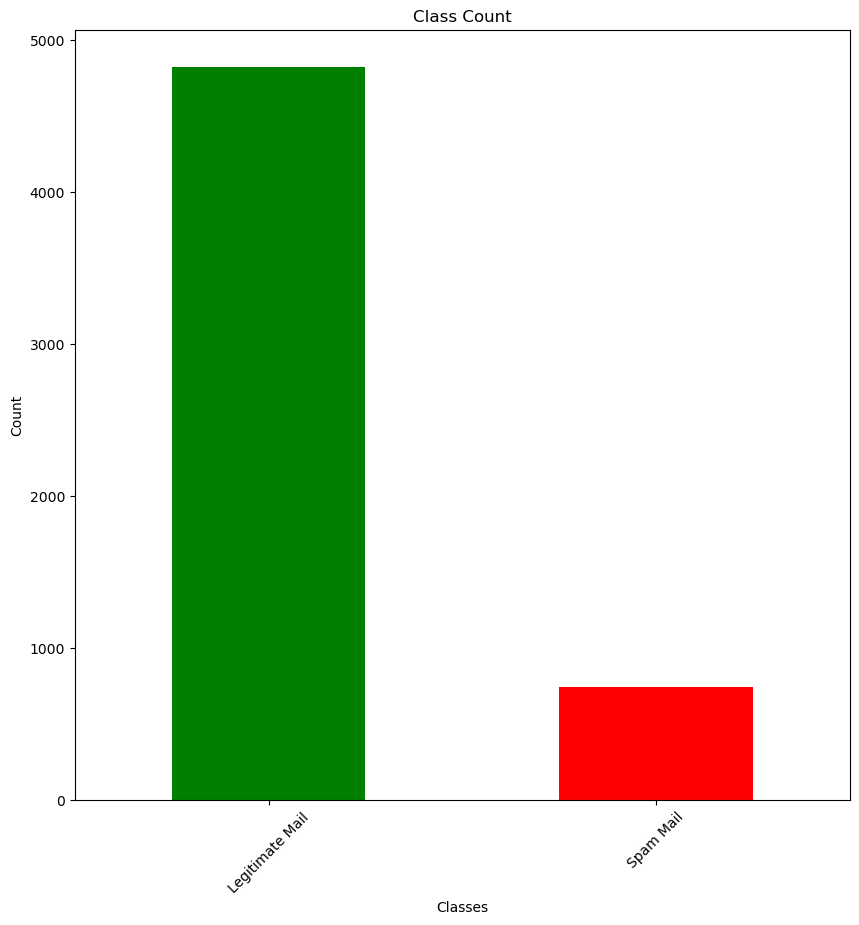

In [543]:
mail_data['class'].value_counts().plot(
    kind = 'bar',
    xlabel = 'Classes',
    ylabel = 'Count',
    title = 'Class Count',
    figsize = (10, 10),
    color = ['green','red'],
    rot = 45
)
plt.show()

In [544]:
mail_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   class    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [545]:
mail_data.dtypes

class      object
message    object
dtype: object

In [546]:
mail_data.describe()

,class,message
count,5572,5572
unique,2,5169
top,Legitimate Mail,"Sorry, I'll call later"
freq,4825,30


In [547]:
mail_data.describe().T

,count,unique,top,freq
class,5572,2,Legitimate Mail,4825
message,5572,5169,"Sorry, I'll call later",30


In [548]:
mail_data.isnull()

,class,message
0,False,False
1,False,False
2,False,False
3,False,False
4,False,False
...,...,...
5567,False,False
5568,False,False
5569,False,False
5570,False,False


In [549]:
mail_data.isnull().sum()

class      0
message    0
dtype: int64

In [550]:
mail_data.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
5567    False
5568    False
5569    False
5570    False
5571    False
Length: 5572, dtype: bool

In [551]:
mail_data.duplicated().sum()

np.int64(403)

In [552]:
mail_data.drop_duplicates(inplace = True)

In [553]:
mail_data.duplicated().sum()

np.int64(0)

In [554]:
mail_data.shape

(5169, 2)

In [555]:
mail_data.size

10338

In [556]:
mail_data['class'].value_counts()

class
Legitimate Mail    4516
Spam Mail           653
Name: count, dtype: int64

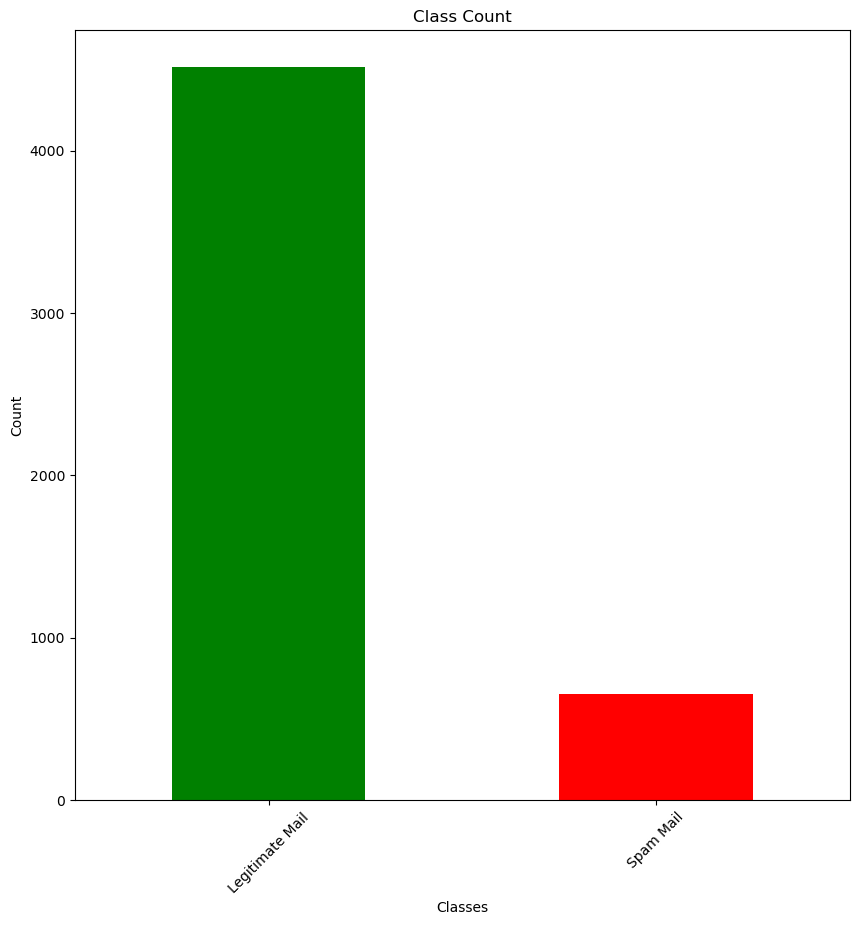

In [557]:
mail_data['class'].value_counts().plot(
    kind = 'bar',
    xlabel = 'Classes',
    ylabel = 'Count',
    title = 'Class Count',
    figsize = (10, 10),
    color = ['green','red'],
    rot = 45
)
plt.show()

In [558]:
mail_data

,class,message
0,Legitimate Mail,"Go until jurong point, crazy.. Available only ..."
1,Legitimate Mail,Ok lar... Joking wif u oni...
2,Spam Mail,Free entry in 2 a wkly comp to win FA Cup fina...
3,Legitimate Mail,U dun say so early hor... U c already then say...
4,Legitimate Mail,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,Spam Mail,This is the 2nd time we have tried 2 contact u...
5568,Legitimate Mail,Will Ì_ b going to esplanade fr home?
5569,Legitimate Mail,"Pity, * was in mood for that. So...any other s..."
5570,Legitimate Mail,The guy did some bitching but I acted like i'd...


In [559]:
mail_data['message_length'] = mail_data['message'].apply(len)
mail_data['message_length'] 

0       111
1        29
2       155
3        49
4        61
       ... 
5567    161
5568     37
5569     57
5570    125
5571     26
Name: message_length, Length: 5169, dtype: int64

In [560]:
mail_data

,class,message,message_length
0,Legitimate Mail,"Go until jurong point, crazy.. Available only ...",111
1,Legitimate Mail,Ok lar... Joking wif u oni...,29
2,Spam Mail,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,Legitimate Mail,U dun say so early hor... U c already then say...,49
4,Legitimate Mail,"Nah I don't think he goes to usf, he lives aro...",61
...,...,...,...
5567,Spam Mail,This is the 2nd time we have tried 2 contact u...,161
5568,Legitimate Mail,Will Ì_ b going to esplanade fr home?,37
5569,Legitimate Mail,"Pity, * was in mood for that. So...any other s...",57
5570,Legitimate Mail,The guy did some bitching but I acted like i'd...,125


In [561]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to C:\Users\Jeevan
[nltk_data]     Santosh\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [562]:
stop_words = set(stopwords.words('english'))
stop_words

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'her',
 'here',
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [563]:
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to C:\Users\Jeevan
[nltk_data]     Santosh\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [564]:
# Preprocessing
import re
import string
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'\S+@\S+', '', text)
    text = re.sub(r'\d+', '', text)
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    words = text.split()

    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

In [565]:
mail_data['clean_message'] = mail_data['message'].apply(preprocess)
mail_data['clean_message']

0       go jurong point crazy available bugis n great ...
1                                 ok lar joking wif u oni
2       free entry wkly comp win fa cup final tkts st ...
3                     u dun say early hor u c already say
4                nah dont think go usf life around though
                              ...                        
5567    nd time tried contact u u å£ pound prize claim...
5568                          ì b going esplanade fr home
5569                           pity mood soany suggestion
5570    guy bitching acted like id interested buying s...
5571                                       rofl true name
Name: clean_message, Length: 5169, dtype: object

In [566]:
mail_data

,class,message,message_length,clean_message
0,Legitimate Mail,"Go until jurong point, crazy.. Available only ...",111,go jurong point crazy available bugis n great ...
1,Legitimate Mail,Ok lar... Joking wif u oni...,29,ok lar joking wif u oni
2,Spam Mail,Free entry in 2 a wkly comp to win FA Cup fina...,155,free entry wkly comp win fa cup final tkts st ...
3,Legitimate Mail,U dun say so early hor... U c already then say...,49,u dun say early hor u c already say
4,Legitimate Mail,"Nah I don't think he goes to usf, he lives aro...",61,nah dont think go usf life around though
...,...,...,...,...
5567,Spam Mail,This is the 2nd time we have tried 2 contact u...,161,nd time tried contact u u å£ pound prize claim...
5568,Legitimate Mail,Will Ì_ b going to esplanade fr home?,37,ì b going esplanade fr home
5569,Legitimate Mail,"Pity, * was in mood for that. So...any other s...",57,pity mood soany suggestion
5570,Legitimate Mail,The guy did some bitching but I acted like i'd...,125,guy bitching acted like id interested buying s...


In [567]:
mail_data.shape

(5169, 4)

In [568]:
mail_data.size

20676

In [569]:
mail_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5169 entries, 0 to 5571
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   class           5169 non-null   object
 1   message         5169 non-null   object
 2   message_length  5169 non-null   int64 
 3   clean_message   5169 non-null   object
dtypes: int64(1), object(3)
memory usage: 201.9+ KB


In [570]:
mail_data.dtypes

class             object
message           object
message_length     int64
clean_message     object
dtype: object

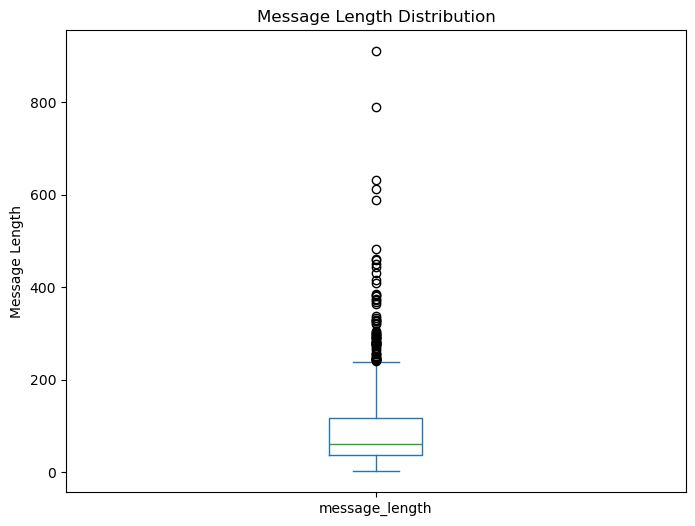

In [571]:
plt.figure(figsize=(8, 6))

mail_data['message_length'].plot(
    kind='box'
)

plt.title('Message Length Distribution')
plt.ylabel('Message Length')
plt.show()

In [572]:
Q1 = mail_data['message_length'].quantile(0.25)
print(Q1)
Q3 = mail_data['message_length'].quantile(0.75)
print(Q3)

# IQR
IQR = Q3 - Q1
print(IQR)

# lower bound and upper bound
lb = Q1 - 1.5 * IQR
print(lb)
ub = Q3 + 1.5 * IQR
print(ub)

36.0
117.0
81.0
-85.5
238.5


In [573]:
mail_data['message_length'] = mail_data['message_length'].clip(lb, ub)
mail_data['message_length']

0       111.0
1        29.0
2       155.0
3        49.0
4        61.0
        ...  
5567    161.0
5568     37.0
5569     57.0
5570    125.0
5571     26.0
Name: message_length, Length: 5169, dtype: float64

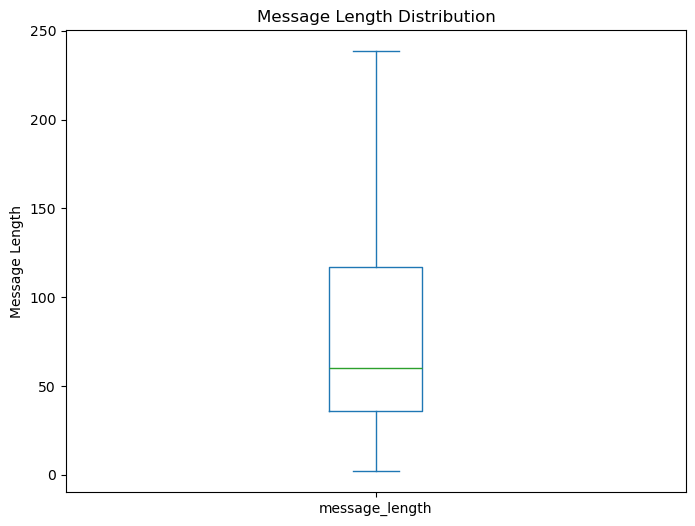

In [574]:
plt.figure(figsize=(8, 6))

mail_data['message_length'].plot(
    kind='box'
)

plt.title('Message Length Distribution')
plt.ylabel('Message Length')
plt.show()

In [575]:
mail_data

,class,message,message_length,clean_message
0,Legitimate Mail,"Go until jurong point, crazy.. Available only ...",111.0,go jurong point crazy available bugis n great ...
1,Legitimate Mail,Ok lar... Joking wif u oni...,29.0,ok lar joking wif u oni
2,Spam Mail,Free entry in 2 a wkly comp to win FA Cup fina...,155.0,free entry wkly comp win fa cup final tkts st ...
3,Legitimate Mail,U dun say so early hor... U c already then say...,49.0,u dun say early hor u c already say
4,Legitimate Mail,"Nah I don't think he goes to usf, he lives aro...",61.0,nah dont think go usf life around though
...,...,...,...,...
5567,Spam Mail,This is the 2nd time we have tried 2 contact u...,161.0,nd time tried contact u u å£ pound prize claim...
5568,Legitimate Mail,Will Ì_ b going to esplanade fr home?,37.0,ì b going esplanade fr home
5569,Legitimate Mail,"Pity, * was in mood for that. So...any other s...",57.0,pity mood soany suggestion
5570,Legitimate Mail,The guy did some bitching but I acted like i'd...,125.0,guy bitching acted like id interested buying s...


In [576]:
# Feature Variable
X = mail_data['clean_message']
X

0       go jurong point crazy available bugis n great ...
1                                 ok lar joking wif u oni
2       free entry wkly comp win fa cup final tkts st ...
3                     u dun say early hor u c already say
4                nah dont think go usf life around though
                              ...                        
5567    nd time tried contact u u å£ pound prize claim...
5568                          ì b going esplanade fr home
5569                           pity mood soany suggestion
5570    guy bitching acted like id interested buying s...
5571                                       rofl true name
Name: clean_message, Length: 5169, dtype: object

In [577]:
y = mail_data['class']
y

0       Legitimate Mail
1       Legitimate Mail
2             Spam Mail
3       Legitimate Mail
4       Legitimate Mail
             ...       
5567          Spam Mail
5568    Legitimate Mail
5569    Legitimate Mail
5570    Legitimate Mail
5571    Legitimate Mail
Name: class, Length: 5169, dtype: object

In [578]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

In [579]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()
vectorizer

,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None
,analyzer,'word'
,stop_words,None
,token_pattern,'(?u)\\b\\w\\w+\\b'
,ngram_range,"(1, ...)"


In [580]:
X = vectorizer.fit_transform(mail_data['clean_message'])
X

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 41353 stored elements and shape (5169, 7840)>

In [581]:
vectorizer.get_feature_names_out()

array(['aa', 'aah', 'aaniye', ..., 'ûïharry', 'ûò', 'ûówell'],
      shape=(7840,), dtype=object)

In [582]:
print(vectorizer.get_feature_names_out()[:20])

['aa' 'aah' 'aaniye' 'aaooooright' 'aathilove' 'aathiwhere' 'ab' 'abbey'
 'abdomen' 'abeg' 'abel' 'aberdeen' 'abi' 'ability' 'abiola' 'abj' 'able'
 'abnormally' 'aboutas' 'abroad']


In [583]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 50, stratify = y)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(4135, 7840)
(1034, 7840)
(4135,)
(1034,)


In [584]:
cross_validation = StratifiedKFold(n_splits=5, random_state=None, shuffle=False)
cross_validation

StratifiedKFold(n_splits=5, random_state=None, shuffle=False)

In [585]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(C = 1.0, tol = 0.0001, random_state = 42)
logreg

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [586]:
logreg.get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': None,
 'max_iter': 100,
 'multi_class': 'deprecated',
 'n_jobs': None,
 'penalty': 'l2',
 'random_state': 42,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

In [587]:
lr_param = {
    'fit_intercept' : [True, False],
    'class_weight' : [None, 'balanced'],
    'solver' : ['lbfgs','liblinear','saga'],
    'penalty' : ['l1','l2','elasticnet']
}
lr_param

{'fit_intercept': [True, False],
 'class_weight': [None, 'balanced'],
 'solver': ['lbfgs', 'liblinear', 'saga'],
 'penalty': ['l1', 'l2', 'elasticnet']}

In [588]:
grid_lr = GridSearchCV(
    estimator = logreg,
    param_grid = lr_param,
    cv = cross_validation
)
grid_lr

,estimator,LogisticRegre...ndom_state=42)
,param_grid,"{'class_weight': [None, 'balanced'], 'fit_intercept': [True, False], 'penalty': ['l1', 'l2', ...], 'solver': ['lbfgs', 'liblinear', ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,StratifiedKFo...shuffle=False)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [589]:
grid_lr.fit(X_train, y_train)

,estimator,LogisticRegre...ndom_state=42)
,param_grid,"{'class_weight': [None, 'balanced'], 'fit_intercept': [True, False], 'penalty': ['l1', 'l2', ...], 'solver': ['lbfgs', 'liblinear', ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,StratifiedKFo...shuffle=False)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [590]:
print(grid_lr.best_params_)

{'class_weight': 'balanced', 'fit_intercept': True, 'penalty': 'l2', 'solver': 'lbfgs'}


In [591]:
best_lr = grid_lr.best_estimator_
best_lr

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [592]:
grid_lr.classes_

array(['Legitimate Mail', 'Spam Mail'], dtype=object)

In [593]:
lr_train_pred = best_lr.predict(X_train)
lr_train_pred

array(['Legitimate Mail', 'Legitimate Mail', 'Legitimate Mail', ...,
       'Legitimate Mail', 'Spam Mail', 'Legitimate Mail'],
      shape=(4135,), dtype=object)

In [594]:
lr_train_cm = confusion_matrix(y_train, lr_train_pred)
print(lr_train_cm)

[[3575   38]
 [   3  519]]


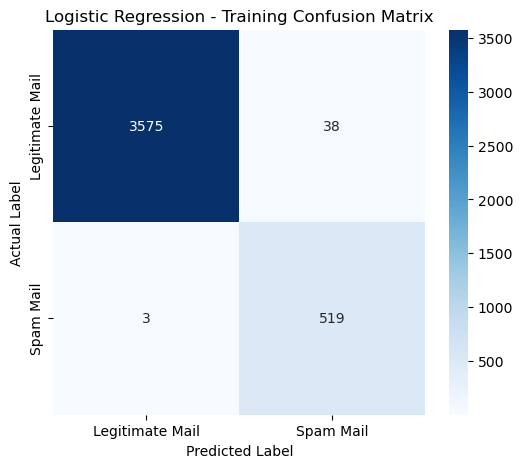

In [595]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    lr_train_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_lr.classes_,
    yticklabels=best_lr.classes_
)

plt.title('Logistic Regression - Training Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [596]:
lr_train_cr = classification_report(y_train, lr_train_pred)
print(lr_train_cr)

                 precision    recall  f1-score   support

Legitimate Mail       1.00      0.99      0.99      3613
      Spam Mail       0.93      0.99      0.96       522

       accuracy                           0.99      4135
      macro avg       0.97      0.99      0.98      4135
   weighted avg       0.99      0.99      0.99      4135



In [597]:
lr_train_acc = accuracy_score(y_train, lr_train_pred)
print(f'The Accuracy of Training in Logistic Regression is {round(lr_train_acc * 100,0)}%.')

lr_train_prec_1 = precision_score(y_train, lr_train_pred, pos_label = 'Spam Mail')
print(f'The Precision of Training in Logistic Regression for Spam Mail is {round(lr_train_prec_1*100, 0)}%')

lr_train_prec_2 = precision_score(y_train, lr_train_pred, pos_label = 'Legitimate Mail')
print(f'The Precision of Training in Logistic Regression for Legitimate Mail is {round(lr_train_prec_2*100, 0)}%')

lr_train_rec_1 = recall_score(y_train, lr_train_pred, pos_label = 'Spam Mail')
print(f'The Recall of Training in Logistic Regression for Spam Mail is {round(lr_train_rec_1*100, 0)}%')

lr_train_rec_2 = recall_score(y_train, lr_train_pred, pos_label = 'Legitimate Mail')
print(f'The Recall of Training in Logistic Regression for Legitimate Mail is {round(lr_train_rec_2*100, 0)}%')

lr_train_f1_1 = f1_score(y_train, lr_train_pred, pos_label = 'Spam Mail')
print(f'The F1-Score of Training in Logistic Regression for Spam Mail is {round(lr_train_f1_1*100, 0)}%')

lr_train_f1_2 = f1_score(y_train, lr_train_pred, pos_label = 'Legitimate Mail')
print(f'The F1-Score of Training in Logistic Regression for Legitimate Mail is {round(lr_train_f1_2*100, 0)}%')

The Accuracy of Training in Logistic Regression is 99.0%.
The Precision of Training in Logistic Regression for Spam Mail is 93.0%
The Precision of Training in Logistic Regression for Legitimate Mail is 100.0%
The Recall of Training in Logistic Regression for Spam Mail is 99.0%
The Recall of Training in Logistic Regression for Legitimate Mail is 99.0%
The F1-Score of Training in Logistic Regression for Spam Mail is 96.0%
The F1-Score of Training in Logistic Regression for Legitimate Mail is 99.0%


In [598]:
lr_test_pred = best_lr.predict(X_test)
lr_test_pred

array(['Legitimate Mail', 'Legitimate Mail', 'Legitimate Mail', ...,
       'Legitimate Mail', 'Legitimate Mail', 'Legitimate Mail'],
      shape=(1034,), dtype=object)

In [599]:
lr_test_cm = confusion_matrix(y_test, lr_test_pred)
print(lr_test_cm)

[[884  19]
 [ 19 112]]


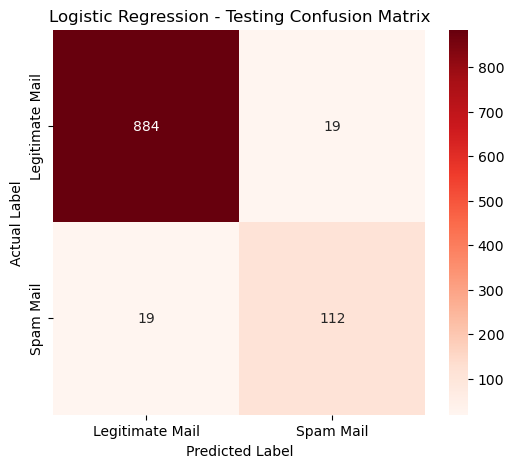

In [600]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    lr_test_cm,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=grid_lr.classes_,
    yticklabels=grid_lr.classes_
)

plt.title('Logistic Regression - Testing Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [601]:
lr_test_cr = classification_report(y_test, lr_test_pred)
print(lr_test_cr)

                 precision    recall  f1-score   support

Legitimate Mail       0.98      0.98      0.98       903
      Spam Mail       0.85      0.85      0.85       131

       accuracy                           0.96      1034
      macro avg       0.92      0.92      0.92      1034
   weighted avg       0.96      0.96      0.96      1034



In [602]:
lr_test_acc = accuracy_score(y_test, lr_test_pred)
print(f'The Accuracy of Testing in Logistic Regression is {round(lr_test_acc * 100,0)}%.')

lr_test_prec_1 = precision_score(y_test, lr_test_pred, pos_label = 'Spam Mail')
print(f'The Precision of Testing in Logistic Regression for Spam Mail is {round(lr_test_prec_1*100, 0)}%')

lr_test_prec_2 = precision_score(y_test, lr_test_pred, pos_label = 'Legitimate Mail')
print(f'The Precision of Testing in Logistic Regression for Legitimate Mail is {round(lr_test_prec_2*100, 0)}%')

lr_test_rec_1 = recall_score(y_test, lr_test_pred, pos_label = 'Spam Mail')
print(f'The Recall of Testing in Logistic Regression for Spam Mail is {round(lr_test_rec_1*100, 0)}%')

lr_test_rec_2 = recall_score(y_test, lr_test_pred, pos_label = 'Legitimate Mail')
print(f'The Recall of Testing in Logistic Regression for Legitimate Mail is {round(lr_test_rec_2*100, 0)}%')

lr_test_f1_1 = f1_score(y_test, lr_test_pred, pos_label = 'Spam Mail')
print(f'The F1-Score of Testing in Logistic Regression for Spam Mail is {round(lr_test_f1_1*100, 0)}%')

lr_test_f1_2 = f1_score(y_test, lr_test_pred, pos_label = 'Legitimate Mail')
print(f'The F1-Score of Testing in Logistic Regression for Legitimate Mail is {round(lr_test_f1_2*100, 0)}%')

The Accuracy of Testing in Logistic Regression is 96.0%.
The Precision of Testing in Logistic Regression for Spam Mail is 85.0%
The Precision of Testing in Logistic Regression for Legitimate Mail is 98.0%
The Recall of Testing in Logistic Regression for Spam Mail is 85.0%
The Recall of Testing in Logistic Regression for Legitimate Mail is 98.0%
The F1-Score of Testing in Logistic Regression for Spam Mail is 85.0%
The F1-Score of Testing in Logistic Regression for Legitimate Mail is 98.0%


In [603]:
lr_difference = round(abs(lr_test_acc - lr_train_acc)*100,0)
lr_difference

3.0

In [604]:
if lr_difference < 5:
    print("The model is generalizing well")
elif lr_difference < 10:
    print("The model is slightly overfitting")
else:
    print("The model is overfitting")

The model is generalizing well


In [605]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [606]:
nb_model.get_params()

{'alpha': 1.0, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}

In [607]:
nb_param = {
    'alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0],
    'fit_prior': [True, False]
}
nb_param

{'alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0], 'fit_prior': [True, False]}

In [608]:
grid_nb = GridSearchCV(
    estimator = nb_model,
    param_grid = nb_param,
    cv = cross_validation
)
grid_nb

,estimator,MultinomialNB()
,param_grid,"{'alpha': [0.01, 0.1, ...], 'fit_prior': [True, False]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,StratifiedKFo...shuffle=False)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,1.0


In [609]:
grid_nb.fit(X_train, y_train)

,estimator,MultinomialNB()
,param_grid,"{'alpha': [0.01, 0.1, ...], 'fit_prior': [True, False]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,StratifiedKFo...shuffle=False)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,alpha,0.5


In [610]:
print("Best Parameters:", grid_nb.best_params_)

Best Parameters: {'alpha': 0.5, 'fit_prior': True}


In [611]:
best_nb = grid_nb.best_estimator_
best_nb

,alpha,0.5
,force_alpha,True
,fit_prior,True
,class_prior,None


In [612]:
best_nb.classes_

array(['Legitimate Mail', 'Spam Mail'], dtype='<U15')

In [613]:
nb_train_pred = best_nb.predict(X_train)
nb_train_pred

array(['Legitimate Mail', 'Legitimate Mail', 'Legitimate Mail', ...,
       'Legitimate Mail', 'Spam Mail', 'Legitimate Mail'],
      shape=(4135,), dtype='<U15')

In [614]:
nb_train_cm = confusion_matrix(y_train, nb_train_pred)
print(nb_train_cm)

[[3613    0]
 [  59  463]]


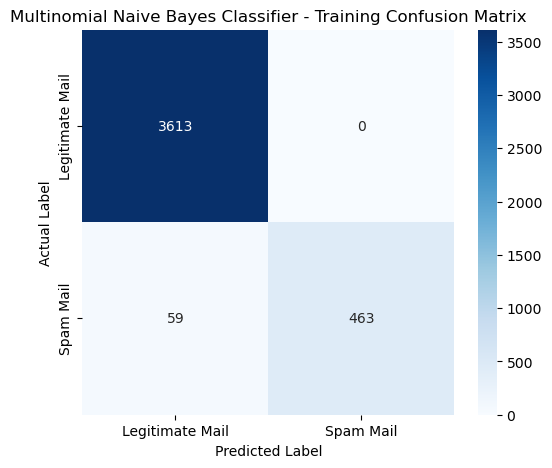

In [615]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    nb_train_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_nb.classes_,
    yticklabels=best_nb.classes_
)

plt.title('Multinomial Naive Bayes Classifier - Training Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [616]:
nb_train_cr = classification_report(y_train, lr_train_pred)
print(nb_train_cr)

                 precision    recall  f1-score   support

Legitimate Mail       1.00      0.99      0.99      3613
      Spam Mail       0.93      0.99      0.96       522

       accuracy                           0.99      4135
      macro avg       0.97      0.99      0.98      4135
   weighted avg       0.99      0.99      0.99      4135



In [617]:
nb_train_acc = accuracy_score(y_train, nb_train_pred)
print(f'The Accuracy of Training in Multinomial Naive Bayes Classifier is {round(nb_train_acc * 100,0)}%.')

nb_train_prec_1 = precision_score(y_train, nb_train_pred, pos_label = 'Spam Mail')
print(f'The Precision of Training in Multinomial Naive Bayes Classifier for Spam Mail is {round(nb_train_prec_1*100, 0)}%')

nb_train_prec_2 = precision_score(y_train, nb_train_pred, pos_label = 'Legitimate Mail')
print(f'The Precision of Training in Multinomial Naive Bayes Classifier for Legitimate Mail is {round(nb_train_prec_2*100, 0)}%')

nb_train_rec_1 = recall_score(y_train, nb_train_pred, pos_label = 'Spam Mail')
print(f'The Recall of Training in Multinomial Naive Bayes Classifier for Spam Mail is {round(nb_train_rec_1*100, 0)}%')

nb_train_rec_2 = recall_score(y_train, nb_train_pred, pos_label = 'Legitimate Mail')
print(f'The Recall of Training in Multinomial Naive Bayes Classifier for Legitimate Mail is {round(nb_train_rec_2*100, 0)}%')

nb_train_f1_1 = f1_score(y_train, nb_train_pred, pos_label = 'Spam Mail')
print(f'The F1-Score of Training in Multinomial Naive Bayes Classifier for Spam Mail is {round(nb_train_f1_1*100, 0)}%')

nb_train_f1_2 = f1_score(y_train, nb_train_pred, pos_label = 'Legitimate Mail')
print(f'The F1-Score of Training in Multinomial Naive Bayes Classifier for Legitimate Mail is {round(nb_train_f1_2*100, 0)}%')

The Accuracy of Training in Multinomial Naive Bayes Classifier is 99.0%.
The Precision of Training in Multinomial Naive Bayes Classifier for Spam Mail is 100.0%
The Precision of Training in Multinomial Naive Bayes Classifier for Legitimate Mail is 98.0%
The Recall of Training in Multinomial Naive Bayes Classifier for Spam Mail is 89.0%
The Recall of Training in Multinomial Naive Bayes Classifier for Legitimate Mail is 100.0%
The F1-Score of Training in Multinomial Naive Bayes Classifier for Spam Mail is 94.0%
The F1-Score of Training in Multinomial Naive Bayes Classifier for Legitimate Mail is 99.0%


In [618]:
nb_test_pred = best_nb.predict(X_test)
nb_test_pred

array(['Legitimate Mail', 'Legitimate Mail', 'Legitimate Mail', ...,
       'Legitimate Mail', 'Legitimate Mail', 'Legitimate Mail'],
      shape=(1034,), dtype='<U15')

In [619]:
nb_test_cm = confusion_matrix(y_test, nb_test_pred)
print(nb_test_cm)

[[901   2]
 [ 30 101]]


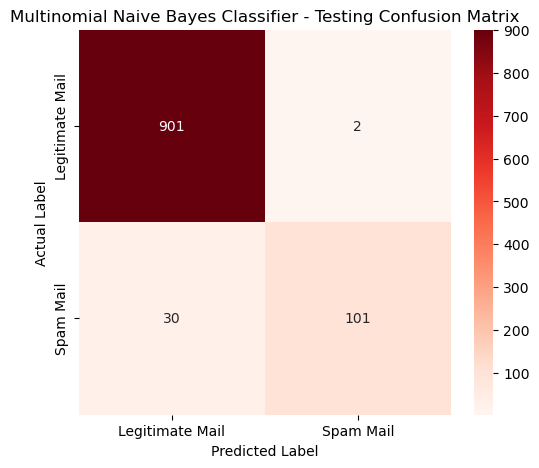

In [620]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    nb_test_cm,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=best_nb.classes_,
    yticklabels=best_nb.classes_
)

plt.title('Multinomial Naive Bayes Classifier - Testing Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [621]:
nb_test_cr = classification_report(y_test, lr_test_pred)
print(nb_test_cr)

                 precision    recall  f1-score   support

Legitimate Mail       0.98      0.98      0.98       903
      Spam Mail       0.85      0.85      0.85       131

       accuracy                           0.96      1034
      macro avg       0.92      0.92      0.92      1034
   weighted avg       0.96      0.96      0.96      1034



In [622]:
nb_test_acc = accuracy_score(y_test, lr_test_pred)
print(f'The Accuracy of Testing in Multinomial Naive Bayes Classifier is {round(nb_test_acc * 100,0)}%.')

nb_test_prec_1 = precision_score(y_test, lr_test_pred, pos_label = 'Spam Mail')
print(f'The Precision of Testing in Multinomial Naive Bayes Classifier for Spam Mail is {round(nb_test_prec_1*100, 0)}%')

nb_test_prec_2 = precision_score(y_test, lr_test_pred, pos_label = 'Legitimate Mail')
print(f'The Precision of Testing in Multinomial Naive Bayes Classifier for Legitimate Mail is {round(nb_test_prec_2*100, 0)}%')

nb_test_rec_1 = recall_score(y_test, lr_test_pred, pos_label = 'Spam Mail')
print(f'The Recall of Testing in Multinomial Naive Bayes Classifier for Spam Mail is {round(nb_test_rec_1*100, 0)}%')

nb_test_rec_2 = recall_score(y_test, lr_test_pred, pos_label = 'Legitimate Mail')
print(f'The Recall of Testing in Multinomial Naive Bayes Classifier for Legitimate Mail is {round(nb_test_rec_2*100, 0)}%')

nb_test_f1_1 = f1_score(y_test, lr_test_pred, pos_label = 'Spam Mail')
print(f'The F1-Score of Testing in Multinomial Naive Bayes Classifier for Spam Mail is {round(nb_test_f1_1*100, 0)}%')
y_test
nb_test_f1_2 = f1_score(y_test, lr_test_pred, pos_label = 'Legitimate Mail')
print(f'The F1-Score of Testing in Multinomial Naive Bayes Classifier for Legitimate Mail is {round(nb_test_f1_2*100, 0)}%')

The Accuracy of Testing in Multinomial Naive Bayes Classifier is 96.0%.
The Precision of Testing in Multinomial Naive Bayes Classifier for Spam Mail is 85.0%
The Precision of Testing in Multinomial Naive Bayes Classifier for Legitimate Mail is 98.0%
The Recall of Testing in Multinomial Naive Bayes Classifier for Spam Mail is 85.0%
The Recall of Testing in Multinomial Naive Bayes Classifier for Legitimate Mail is 98.0%
The F1-Score of Testing in Multinomial Naive Bayes Classifier for Spam Mail is 85.0%
The F1-Score of Testing in Multinomial Naive Bayes Classifier for Legitimate Mail is 98.0%


In [623]:
nb_difference = round(abs(nb_test_acc - nb_train_acc)*100,0)
nb_difference

2.0

In [624]:
if nb_difference < 5:
    print("The model is generalizing well")
elif nb_difference < 10:
    print("The model is slightly overfitting")
else:
    print("The model is overfitting")

The model is generalizing well


In [625]:
if lr_test_acc > nb_test_acc:
    print("Selected Model: Logistic Regression")
    print("Reason: Higher testing accuracy.")

elif nb_test_acc > lr_test_acc:
    print("Selected Model: Naive Bayes")
    print("Reason: Higher testing accuracy.")

else:
    print("Selected Model: Both Models")
    print("Reason: Both achieved the same testing accuracy.")

Selected Model: Both Models
Reason: Both achieved the same testing accuracy.


In [626]:
import joblib

In [627]:
joblib.dump(vectorizer, "models/tfidf_vectorizer.pkl")

['models/tfidf_vectorizer.pkl']

In [628]:
joblib.dump(best_lr, "models/best_lr.pkl")

['models/best_lr.pkl']

In [629]:
joblib.dump(best_nb, "models/best_nb.pkl")

['models/best_nb.pkl']

In [630]:
test_msg = ["Congratulations! You won a FREE iPhone. Claim your prize now!"]

test_vector = vectorizer.transform(test_msg)

print("LR:", best_lr.predict(test_vector)[0])
print("NB:", best_nb.predict(test_vector)[0])

LR: Spam Mail
NB: Spam Mail
